# $Meta-I$


#### Background
Meta-I is a measure of metacognitive sensitivity as proposed by Dayan (2023). It essentially quantifies how much our own confidence in a choice can tell us about being right.
Meta-I looks at how much the confidence ratings reduces of the **uncertainty about accuracy** using mutual information:
$$\text{meta-I} = H_2(r) - H_2(r \mid c)$$

in which $H_2(r)$ is the entropy of the accuracy, and $H_2(r\mid c)$ is the remaining entropy about accuracy after seeing the confidence rating $c$. Meta-I is 0, when the confidence tells us nothing about accuracy and approaches $H_2(r)$, the more confidence predicts accuracy.

It is the mutual information between accuracy of the choice and the confidence in that choice expressed in bits.
Metacognitive sensitivity is tied to the ability to reflect accuracy in the confidence rating about that choice, so ideally confidence should be higher for correct and lower for incorrect choices.


Dayan additionally proposed two types of metacognitive efficiency:

 - **Meta-Ir1** = $meta-I / meta-I(d′)$: mutual information is normalized by the mutual information a naive Baysian observer would produce idealy given a certain d' (type 1 SDT perceptual sensitivity).

 - **Meta-Ir2** = $meta-I / H₂(r)$: mutual information is normalized by $H_2(r)$ the total uncertainty there is about accuracy in the first place (theoretical upper bound of meta-I).  
<br>
<br>

The measures implemented are based on:
> Dayan, P. (2023). Metacognitive Information Theory.  
> Open Mind: Discoveries in Cognitive Science.  
> https://doi.org/10.1162/opmi_a_00091

In [2]:
import cpm
import numpy as nump
import pandas as pd
import scipy.stats

### Exploring the data
The data was collected using the BrainExplorer app's Space Observer task, where participants have to decide which type of alien (e.g. green vs orange) is more numerous and after that report their confidence in that choice by choosing a position on a slider.

In [3]:
from cpm.datasets import load_metacognition_data

df = load_metacognition_data()
df.head()

,participant,signal,stimulus_intensity,response,confidence,accuracy
0,1,1,8,0,56,0
1,1,0,12,0,65,1
2,1,0,12,1,22,0
3,1,1,16,1,62,1
4,1,0,16,0,60,1


The columns:
- `signal`: type of alien more numerous (S1=0, S2=1) with amount of stimulus_intensity
- `stimulus_intensity`: the absolute difference betweent the number of aliens (ranges between 2-34)`
- `response`: decision/choice of the participant (S1=0, S2=1)
- `confidence`: continous confidence rating (in this case 0-100)
- `accuracy`: whether participants choice (response) was correct (consistent with the stimulus).

### Estimating meta-d'

In [4]:
import warnings

from cpm.applications.signal_detection import EstimatorMetaD

warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", message="delta_grad == 0.0")

df["observed"] = df["confidence"]

estimator_metad = EstimatorMetaD(
    data= df.groupby("participant"),
    bins=4,
    prior=True
)

estimator_metad.optimise()
results_metad = estimator_metad.export()

Correcting for bias in high confidence ratings
Correcting for bias in high confidence ratings
Correction for bias in low confidence ratings
Correction for bias in low confidence ratings
Correcting for bias in high confidence ratings
Correcting for bias in high confidence ratings
Correcting for bias in high confidence ratings
Correcting for bias in high confidence ratings
Correcting for bias in high confidence ratings
Correcting for bias in high confidence ratings
Correcting for bias in high confidence ratings
Correcting for bias in high confidence ratings
Correcting for bias in high confidence ratings
Correcting for bias in high confidence ratings
Correcting for bias in high confidence ratings
Correcting for bias in high confidence ratings
Correcting for bias in high confidence ratings
Correcting for bias in high confidence ratings
Correcting for bias in high confidence ratings
Correcting for bias in high confidence ratings
Correcting for bias in high confidence ratings
Correcting for 

### Estimating meta-I

In [5]:
from cpm.applications.metainformation_theoretic import EstimatorMetaI

estimator_metaI = EstimatorMetaI(
    data=df, 
    bins=4, 
    matched_bins=True, 
    ppt_identifier="participant"
)

estimator_metaI.estimate()
results_metaI = estimator_metaI.export()

In [6]:
print(results_metad[["ppt", "d", "meta_d", "m_ratio"]].head())
print(results_metaI[["ppt", "meta_I", "meta_Ir1", "meta_Ir2"]].head())

   ppt         d    meta_d   m_ratio
0    1  1.359242  1.314121  0.966805
1    2  1.029980  0.584894  0.567869
2    3  1.039519  0.405863  0.390434
3    4  1.272349  0.737918  0.579965
4    5  1.256566  1.382703  1.100382
   ppt    meta_I  meta_Ir1  meta_Ir2
0    1  0.087764  1.144397  0.110973
1    2  0.050283  0.986277  0.058099
2    3  0.020070  0.387998  0.023190
3    4  0.020873  0.297237  0.025728
4    5  0.091895  1.329770  0.112582


### Correlating meta-d'and meta-I

In [7]:
meta_d = results_metad["meta_d"]
meta_I = results_metaI["meta_I"]

r, p = scipy.stats.pearsonr(meta_d, meta_I)
print(f" r = {r:.2f}, p = {p:.3f}")

 r = 0.87, p = 0.000


#### Visualize

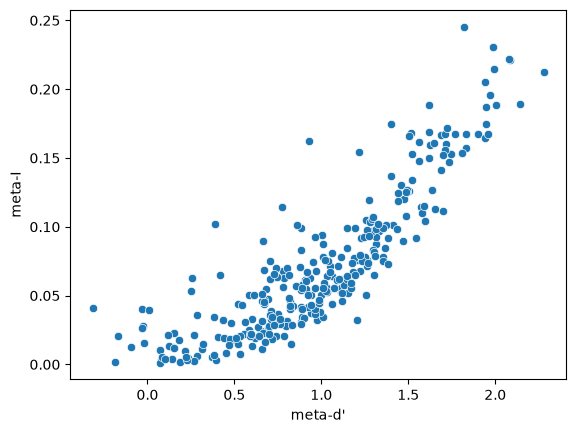

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.scatterplot(x = meta_d, y = meta_I)
plt.xlabel("meta-d'")
plt.ylabel("meta-I")
plt.show()
